# Where the DSMEM workloads sit on the H100 NVL roofline

Every workload of `../workloads/` exists in a version that exchanges data between the CTAs of a thread-block
cluster through distributed shared memory (DSMEM) and in a version that does not. This notebook places both versions
on the roofline of one H100 NVL, measured on the device at a locked SM clock. Inputs: the manifests (`../workloads/*.yaml`),
`../results/ceilings.csv` and `../results/points.csv`; the logic is in `roofline_figures.py`.

In [1]:
import roofline_figures as rf
L = rf.load()
C = L["C"]

## Setup

In [2]:
rf.table_setup(C, L["P"])

,
device,"NVIDIA H100 NVL, 132 SMs (GPU 3)"
driver / CUDA,580.126.20 / 12.9
SM clock,locked at 1635 MHz for every timed and ncu run; memory clock 2619 MHz
ceilings run,2026-10-26T15:19:46.084+00:00
points rows,"10498 (10400 timed reps, 98 counter rows)"


## Definitions

| Term | Meaning |
|---|---|
| ceiling | best sustained rate of one resource, measured by a microbenchmark on this GPU at the locked clock (`../harness/ceilings/`) |
| operational intensity | work (FLOP, or integer ops for integer workloads) per byte moved at one memory level; on the classic roofline the level is HBM |
| datasheet at lock | datasheet peak (quoted at the 1785 MHz maximum clock) × 1635 / 1785, the peak the locked clock allows |
| ridge point | intensity at which a compute ceiling meets the HBM slope: below it a kernel cannot be compute-bound |

## 1. The device at 1635 MHz

The roofline below is drawn from measurements only; dotted lines are the datasheet peaks. Each compute roof starts
where it meets the HBM slope; the dashed lines are the bandwidths of the other memory levels, which bound a kernel
that reuses data from them.

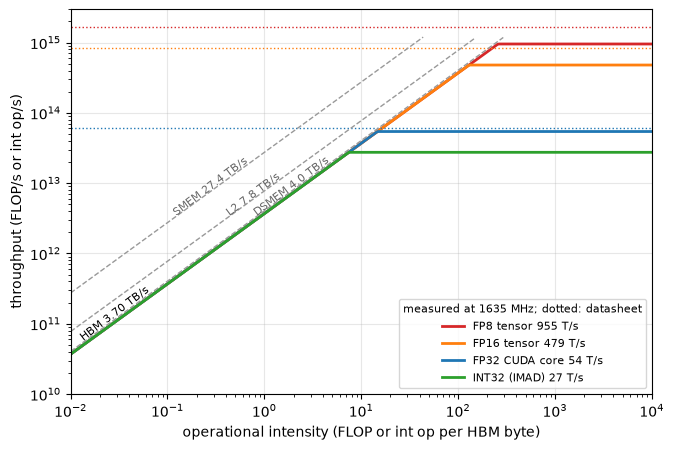

In [3]:
rf.fig_ceilings(C)

In [4]:
rf.table_ceilings(C)

,measured,unit,datasheet,datasheet at lock,measured / datasheet at lock,ridge vs HBM (FLOP/B)
ceiling,,,,,,
FP8 tensor,954.9,TFLOP/s,1670.5,1530.1,62%,258.1
BF16 tensor,526.3,TFLOP/s,835.5,765.3,69%,142.3
FP16 tensor,479.5,TFLOP/s,835.5,765.3,63%,129.6
FP32 CUDA core,54.3,TFLOP/s,60.0,55.0,99%,14.7
INT32 (IMAD),27.5,Tintop/s,—,—,—,7.4
SMEM,27.4,TB/s,—,—,—,—
L2,7.8,TB/s,—,—,—,—
DSMEM,4.0,TB/s,—,—,—,—
HBM,3.7,TB/s,3.9,3.9,95%,—


**Compute.** The FP32 FFMA ceiling reaches 99 % of the datasheet value at the locked clock, so the clock lock and the
measurement are sound. The tensor-core ceilings come from cuBLAS GEMMs of 8192³ and reach 62–69 % of the datasheet
value at the lock: that is what a large library GEMM attains on this card, not the instruction peak. They also only hold
for short bursts. Back-to-back GEMMs drive the card into its 400 W limit and the SM clock falls below the lock
(1605–1620 MHz, once 1485 MHz); the first ceiling run lost 61 of its 100 tensor-core launches to this. The values above
come from launches separated by 1 s of idle time, all at 1635 MHz. Integer IMAD runs at half the FFMA rate (27.5 vs
54.3 T op/s), as the FMA-heavy pipe issues IMAD every other cycle.

**Memory.** HBM reaches 3.70 TB/s read (95 % of the 3.9 TB/s datasheet), L2 7.75 TB/s and shared memory 27.4 TB/s
(128 B per cycle per SM). These are the values microbench experiment 05 measured on GPU 2 of this server, within 1 %.

**DSMEM.** The table below is the aggregate bandwidth when every SM streams to or from a peer in its cluster, with
as many clusters as fit at one CTA per SM.

In [5]:
rf.table_dsmem(C)

,"pull (ld.shared::cluster.v4), TB/s","push (bulk copy), TB/s"
cluster size,,
2,3.54,4.04
4,2.77,3.24
8,2.78,2.93
16,2.59,2.49


The best case, bulk pushes in clusters of 2, reaches 4.04 TB/s, 88 % of the per-SM send limit of the SM-to-SM network
(21.33 B/cycle/SM × 132 SMs × 1.635 GHz = 4.6 TB/s, microbench experiment 11). Larger clusters lose up to 38 %, because
more of the traffic crosses the GPC's shared crossbar. The DSMEM ceiling is therefore only 9 % above the HBM
ceiling and 7× below shared memory: moving data between SMs is not a faster path than reading it from HBM. A DSMEM
port can gain on this roofline in one way only: by moving fewer bytes through HBM (higher intensity), or by replacing
a sequence of kernels whose intermediate results would otherwise make the round trip through memory.

## 2. CREDIT: six row-wise reductions in fp32

Each CREDIT workload processes a matrix row by row and needs one or two statistics of the whole row (a mean, a norm,
a maximum) before it can write the row's output. Three versions exist (`../workloads/credit_*.yaml`):

| role | kernel | how the row statistics are obtained |
|---|---|---|
| non-DSMEM | `block_*_read` | one CTA per row; the row is read from global memory again for every pass over it |
| control | `block_*_staged` | one CTA per row stages the whole row in its shared memory (only while the row fits in 227 KiB) |
| DSMEM | `cluster_*_staged` | a cluster of P CTAs splits the row; each stages its slice in shared memory and the partial statistics are all-reduced through DSMEM |

Rows are 4096, 16384 and 65536 floats (n4k, n16k, n64k), with 4096 rows (2048 for layernorm). P = 2, 4 and 8 were
measured; the marker of the DSMEM version is its fastest P. At 0.1–3.5 FLOP per HBM byte every point lies far left
of the FP32 ridge (14.7 FLOP/B): these kernels are bound by HBM, and the question is how many bytes each version
moves and how fast it moves them.

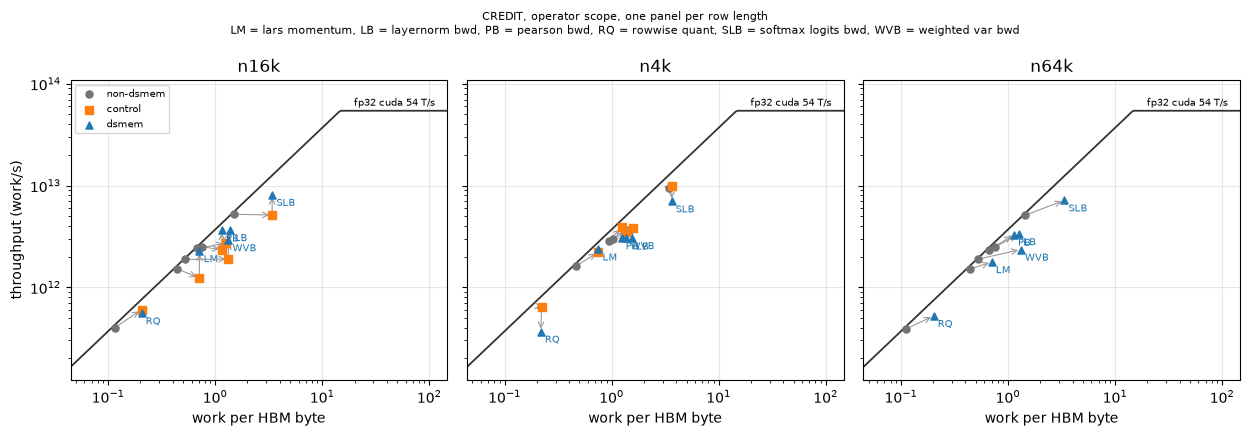

In [6]:
W = [w for w in L["M"] if w.startswith("credit")]
rf.fig_roofline(L, W, title="CREDIT, operator scope, one panel per row length")

In [7]:
rf.table_pairs(L, W)

**Long rows (n16k, n64k): DSMEM wins by reading every input once.** The DSMEM versions are 1.17–1.55× faster than
the one-CTA read kernels. Their HBM traffic is the compulsory traffic (0.96–1.05× of every array read or written once),
while the read kernels move 1.5–2.5× the compulsory bytes: once a row is longer than what the resident CTAs' rows can
keep in the 50 MB of L2, every extra pass over it goes back to HBM. On the roofline the DSMEM marker moves right, to
0.40–0.66× the bytes. The DSMEM traffic itself is negligible: at most 0.01 byte per HBM byte (one or two floats per
CTA per statistic), three orders of magnitude below what the 4.0 TB/s DSMEM ceiling could carry.

**But time falls less than bytes.** The read kernels stream at 3.3–3.6 TB/s (89–97 % of the HBM ceiling); the DSMEM
versions reach 1.8–3.2 TB/s, so they sit further below the HBM slope than the version they replace. The figure below
shows it directly: every pair lies above the diagonal, where a version that kept the read kernel's bandwidth would
sit. The one-CTA staged control loses bandwidth in the same way (1.4–3.0 TB/s at n16k), so the loss comes with staging
the row in shared memory, not with the cluster exchange; the profiles collected here do not identify the mechanism
(occupancy and stall reasons were not measured).

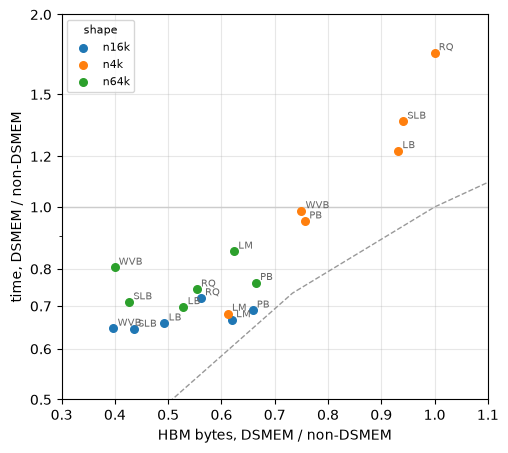

In [8]:
rf.fig_time_vs_bytes(L, W)

**Short rows (n4k): nothing to save.** A 16–48 KB row of the resident CTAs fits in L2, so the read kernel's
second pass hits L2 and it already moves close to the compulsory bytes (0.9–1.5×). The DSMEM version then only adds
cost: it is slower for layernorm, softmax and rowwise quantisation (0.57–0.82×), within 5 % for Pearson and weighted
variance, and faster only for LARS momentum (1.47×), whose three input arrays still overflow L2. Splitting a short
row over more CTAs also multiplies per-row work that every thread of every CTA repeats (precise divisions, block
reductions): for rowwise quantisation the ncu FP32 count reaches 2.25× the per-element formula at n4k with P = 2 and
6× with P = 8. This is why the best P is 2 at n4k, 2–8 at n16k and 8 at n64k.

In [9]:
rf.table_flop_check(L, W)

The table compares the ncu FP32 instruction count (2·FFMA + FADD + FMUL) of each marker with the manifest formula,
the per-element arithmetic as coded (identical in the three kernels). For the one-CTA kernels on long rows the counters
confirm the formula within 1–6 %; rowwise quantisation does 1 FP32 operation per element, so its per-row division alone
adds 16 % at n16k, and short rows add 12–63 %. The DSMEM kernels count 1–33 % more than the formula on long rows and up
to 2.25× on short ones: the per-row work above, done once per CTA, i.e. P times per row. The roofline uses the formula
(the work the computation requires), so this replicated work shows up as lower throughput, not as extra work.